# Entrenamiento de CNN con Transfer Learning
## Objetivos
- Baseline simple con transfer learning usando ResNet18 o VGG16,
- Entrenar solo la cabeza clasificadora (fine-tuning parcial),
- Hacer fine-tuning parcial o total según resultados,
- Guardar métricas por época,
- Guardar el mejor modelo según validación,
- Matriz de confusión y reporte de clasificación final,
- Accuracy, precision, recall y F1-score.

In [1]:
# Importaciones
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torchvision import datasets
from torchvision import transforms as tfs

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from _bootstrap import setup
from src.vasijas.reporting import ProcessingReport

In [2]:
# Configuración general
PATHS = setup()
report = ProcessingReport()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 32
EPOCHS = 12
LR = 1e-3

IMG_SIZE = 224

FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.)
ROTATION_DEGREES = (0, 15)
PIXEL_FILL = (255, 255, 255)

SEED = 42

DATA_DIR = PATHS.DATA_CUADRADOS
MODEL_NAME = "resnet18"

print("Device:", DEVICE)

Device: cpu


In [3]:
# Transformaciones
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.RandomHorizontalFlip(p=FLIP_PROBABILITY),
    # tfs.RandomRotation(degrees=ROTATION_DEGREES, fill=PIXEL_FILL),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transforms = val_transforms


class TransformSubset(Dataset):
    """Subset por indices que aplica transform al vuelo."""

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]  # x es PIL si dataset base no tiene transform
        if self.transform is not None:
            x = self.transform(x)
        return x, y


# a) Dataset base SIN transformaciones
full_dataset = datasets.ImageFolder(DATA_DIR)

indices = np.arange(len(full_dataset))
labels = np.array(full_dataset.targets)

# train vs temp
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# val vs test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

train_dataset = TransformSubset(full_dataset, train_idx, transform=train_transforms)
val_dataset = TransformSubset(full_dataset, val_idx, transform=val_transforms)
test_dataset = TransformSubset(full_dataset, test_idx, transform=test_transforms)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

class_names = full_dataset.classes
NUM_CLASSES = len(class_names)

print("Clases:", class_names)
print(f"Split -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")

Clases: ['clase01', 'clase02', 'clase03', 'clase04', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11']
Split -> train: 756, val: 162, test: 163


In [4]:
from torchvision.models import ResNet18_Weights


# 3. Visualización rápida (sanity check)
def show_batch(loader):
    images, labels = next(iter(loader))
    images = images[:8]
    labels = labels[:8]

    fig, axes = plt.subplots(1, 8, figsize=(16, 3))
    for i, ax in enumerate(axes):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(class_names[labels[i]])
        ax.axis("off")


# Modelo (reemplaza rama resnet18 en get_model)
def get_model(model_name, num_classes):
    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT  # equivalente a IMAGENET1K_V1
        model = models.resnet18(weights=weights, progress=True)

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg16":
        model = models.vgg16(weights="IMAGENET1K_V1")
        for param in model.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    else:
        raise ValueError("Modelo no soportado")

    return model.to(DEVICE)


model = get_model(MODEL_NAME, NUM_CLASSES)

In [5]:
# 5. Funciones de entrenamiento y validación
criterion = nn.CrossEntropyLoss()

# Optimizador (ajusta para entrenar solo lo descongelado)
optimizer = optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc


def validate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc, all_preds, all_labels

In [6]:
# 6. Loop de entrenamiento
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, preds, labels = validate(model, val_loader)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Epoch 1/12
Train Loss: 1.7138 | Train Acc: 0.5013
Val Loss: 1.6578 | Val Acc: 0.5926
Epoch 2/12
Train Loss: 1.1874 | Train Acc: 0.6217
Val Loss: 1.3649 | Val Acc: 0.6667
Epoch 3/12
Train Loss: 0.9506 | Train Acc: 0.7143
Val Loss: 1.0588 | Val Acc: 0.7654
Epoch 4/12
Train Loss: 0.8062 | Train Acc: 0.7632
Val Loss: 0.9078 | Val Acc: 0.8210
Epoch 5/12
Train Loss: 0.7281 | Train Acc: 0.7870
Val Loss: 0.8572 | Val Acc: 0.8210
Epoch 6/12
Train Loss: 0.6497 | Train Acc: 0.8188
Val Loss: 0.8040 | Val Acc: 0.8086
Epoch 7/12
Train Loss: 0.6115 | Train Acc: 0.8214
Val Loss: 0.7452 | Val Acc: 0.8272
Epoch 8/12
Train Loss: 0.5774 | Train Acc: 0.8399
Val Loss: 0.6467 | Val Acc: 0.8519
Epoch 9/12
Train Loss: 0.5605 | Train Acc: 0.8545
Val Loss: 0.6407 | Val Acc: 0.8704
Epoch 10/12
Train Loss: 0.5197 | Train Acc: 0.8585
Val Loss: 0.6536 | Val Acc: 0.8704
Epoch 11/12
Train Loss: 0.4928 | Train Acc: 0.8704
Val Loss: 0.5900 | Val Acc: 0.8642
Epoch 12/12
Train Loss: 0.4675 | Train Acc: 0.8796
Val Loss: 0.

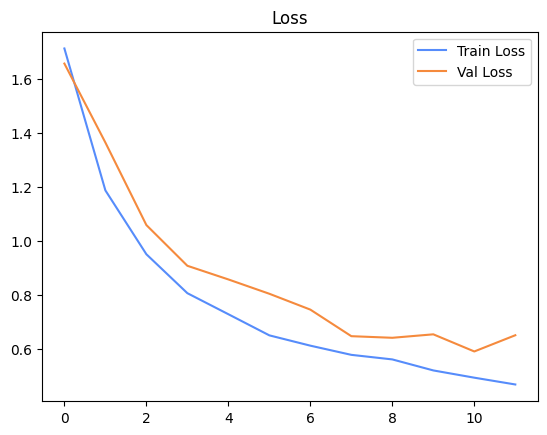

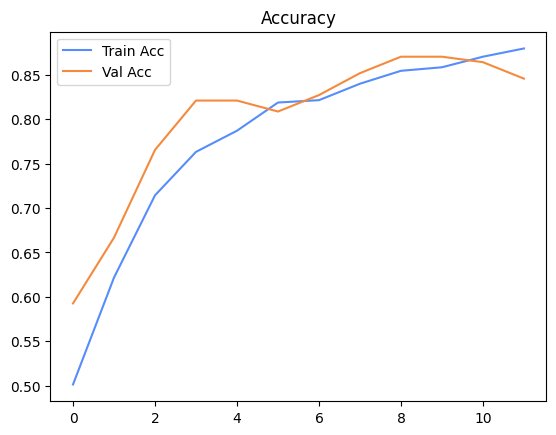

In [7]:
# 7. Curvas de entrenamiento
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()

plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

Test Acc: 0.8282
              precision    recall  f1-score   support

     clase01       1.00      0.50      0.67         4
     clase02       1.00      0.29      0.44         7
     clase03       1.00      0.82      0.90        11
     clase04       0.00      0.00      0.00         1
     clase05       0.88      0.78      0.82         9
     clase06       0.62      0.71      0.67         7
     clase07       0.60      0.43      0.50         7
     clase08       0.73      0.95      0.82        42
     clase09       0.00      0.00      0.00         3
     clase10       0.96      0.91      0.93        54
     clase11       0.78      1.00      0.88        18

    accuracy                           0.83       163
   macro avg       0.69      0.58      0.60       163
weighted avg       0.83      0.83      0.81       163



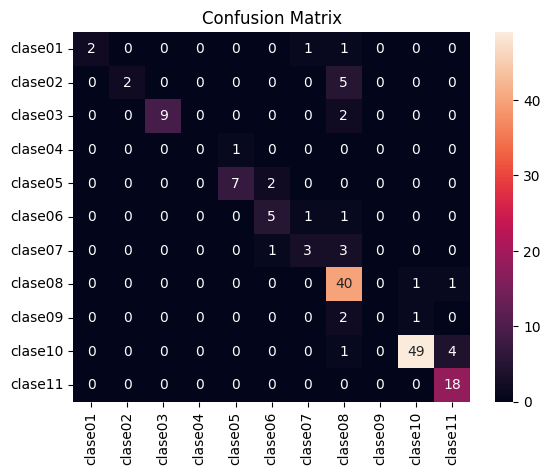

In [8]:
# 8. Evaluación final
_, test_acc, final_preds, final_labels = validate(model, test_loader)
print(f"Test Acc: {test_acc:.4f}")

all_label_ids = list(range(NUM_CLASSES))

print(
    classification_report(
        final_labels,
        final_preds,
        labels=all_label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

cm = confusion_matrix(final_labels, final_preds, labels=all_label_ids)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

In [9]:
# 9. Guardado del modelo
torch.save(model.state_dict(), PATHS.OUTPUT_MODELS / f"{MODEL_NAME}_final.pth")